In [3]:
# Uber Supply Demand Gap Exploratory Data Analytics Project

Project Name - Uber EDA Project



Project Type- EDA
Contribution- Individual
Name - Sanketh S


Project Summary - 

Write the summary here within 500-600 words.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


**Write Problem Statement Here.**

#### **Define Your Business Objective?**

Answer Here.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [4]:

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import plotly.express as px
import random 
from wordcloud import WordCloud
import ast
import statsmodels as stat
import geopandas as geo
import missingno as ms


### Dataset Loading

In [5]:
# Load Dataset
md = pd.read_csv("Uber Request Data.csv")


### Dataset First View

In [6]:
# Dataset First Look
md.head(5)

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
0,619,Airport,1.0,Trip Completed,11/07/16 11:51,11/07/16 13:00
1,867,Airport,1.0,Trip Completed,11/07/16 17:57,11/07/16 18:47
2,1807,City,1.0,Trip Completed,12/07/16 9:17,12/07/16 9:58
3,2532,Airport,1.0,Trip Completed,12/07/16 21:08,12/07/16 22:03
4,3112,City,1.0,Trip Completed,13/07/16 8:33,13/07/16 9:25


In [7]:
# Dataset tail Look
md.tail(5)

,Request id,Pickup point,Driver id,Status,Request timestamp,Drop timestamp
6740,6745,City,NaN,No Cars Available,15/07/16 23:49,NaN
6741,6752,Airport,NaN,No Cars Available,15/07/16 23:50,NaN
6742,6751,City,NaN,No Cars Available,15/07/16 23:52,NaN
6743,6754,City,NaN,No Cars Available,15/07/16 23:54,NaN
6744,6753,Airport,NaN,No Cars Available,15/07/16 23:55,NaN


### Dataset Rows & Columns count

In [8]:
# Dataset Rows & Columns count
md.shape

(6745, 6)

### Dataset Information

In [9]:
# Dataset Info
md.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6745 entries, 0 to 6744
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Request id         6745 non-null   int64  
 1   Pickup point       6745 non-null   object 
 2   Driver id          4095 non-null   float64
 3   Status             6745 non-null   object 
 4   Request timestamp  6745 non-null   object 
 5   Drop timestamp     2831 non-null   object 
dtypes: float64(1), int64(1), object(4)
memory usage: 316.3+ KB


#### Duplicate Values

In [10]:
# Dataset Duplicate Value Count
duplicates = md.duplicated(keep=False)
duplicate_count = duplicates.value_counts()
print(duplicate_count)

False    6745
Name: count, dtype: int64


#### Missing Values/Null Values

In [11]:
# Missing Values/Null Values Count
md.isnull().sum()

Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp       0
Drop timestamp       3914
dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

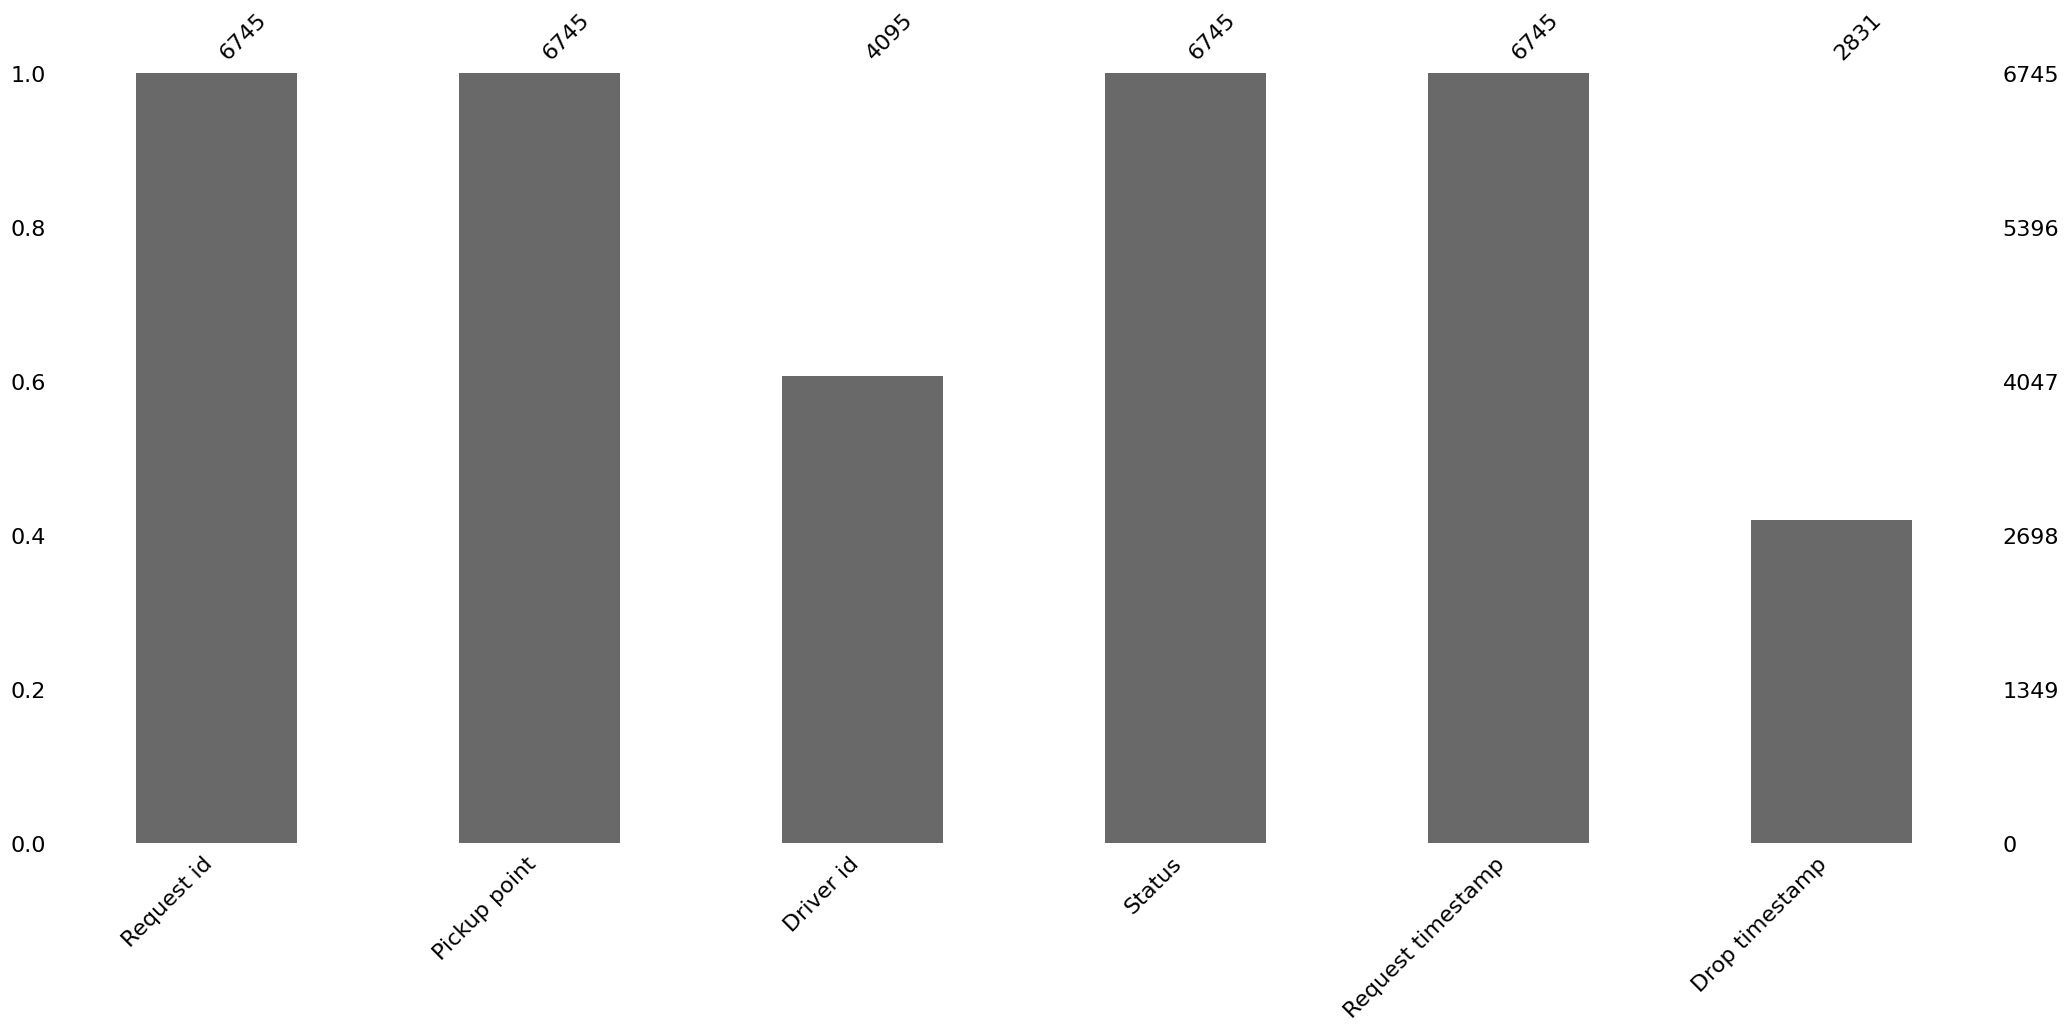

In [12]:
# Visualizing the missing values
ms.bar(md)
plt.show

### What did you know about your dataset?

The Following are the major points about the dataset:
1. The dataset contains 6 columns ans 6745 rows.
2. There are no duplicate values in the dataset.

Following 2 columns are having some missing values:

Driver id - 2650
Drop timestamp - 3914

## ***2. Understanding Your Variables***

In [13]:
# Dataset Columns
md.columns

Index(['Request id', 'Pickup point', 'Driver id', 'Status',
       'Request timestamp', 'Drop timestamp'],
      dtype='object')

In [14]:
# Dataset Describe
md.describe

<bound method NDFrame.describe of       Request id Pickup point  Driver id             Status Request timestamp  \
0            619      Airport        1.0     Trip Completed    11/07/16 11:51   
1            867      Airport        1.0     Trip Completed    11/07/16 17:57   
2           1807         City        1.0     Trip Completed     12/07/16 9:17   
3           2532      Airport        1.0     Trip Completed    12/07/16 21:08   
4           3112         City        1.0     Trip Completed     13/07/16 8:33   
...          ...          ...        ...                ...               ...   
6740        6745         City        NaN  No Cars Available    15/07/16 23:49   
6741        6752      Airport        NaN  No Cars Available    15/07/16 23:50   
6742        6751         City        NaN  No Cars Available    15/07/16 23:52   
6743        6754         City        NaN  No Cars Available    15/07/16 23:54   
6744        6753      Airport        NaN  No Cars Available    15/07/16 23:

### Variables Description

The following are the variables with description:
Column names ----- Description
1. Request id ----- customer unique id who requested for the cab service through app.
2. Pickup point ----- Pickup location to pickup the customer.
3. Driver id ----- Unique id of driver who is driving the cab.
4. Status ----- status of trip that it got completed,cancelled or no cabs available.
5. Request timestamp ----- Request time and date when the customer requested for the cab service.
6. Drop timestamp -----  Drop time and date when the customer is dropped to their respective location.

### Check Unique Values for each variable.

In [15]:
# Check Unique Values for each variable.
for x in md.columns:
    print(f"{x} - {md[x].nunique()}")

Request id - 6745
Pickup point - 2
Driver id - 300
Status - 3
Request timestamp - 4016
Drop timestamp - 2282


## 3. ***Data Wrangling***

### Data Wrangling Code

In [16]:
# Write your code to make your dataset analysis ready.
md.isnull().sum()

Request id              0
Pickup point            0
Driver id            2650
Status                  0
Request timestamp       0
Drop timestamp       3914
dtype: int64

In [17]:
md.fillna({"Driver id": "Not Available"}, inplace=True)

In [18]:
md.fillna({"Drop timestamp": "Not Available"}, inplace=True)

In [19]:
md.isnull().sum()


Request id           0
Pickup point         0
Driver id            0
Status               0
Request timestamp    0
Drop timestamp       0
dtype: int64

### What all manipulations have you done and insights you found?

The following manipulations I have done to my dataset:
1. As there were no duplicates so no issues of removing it.
2. There are total 2 columns having missing values which we replaced with Not Available value.

Driver id - 2650
Drop timestamp - 3914

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

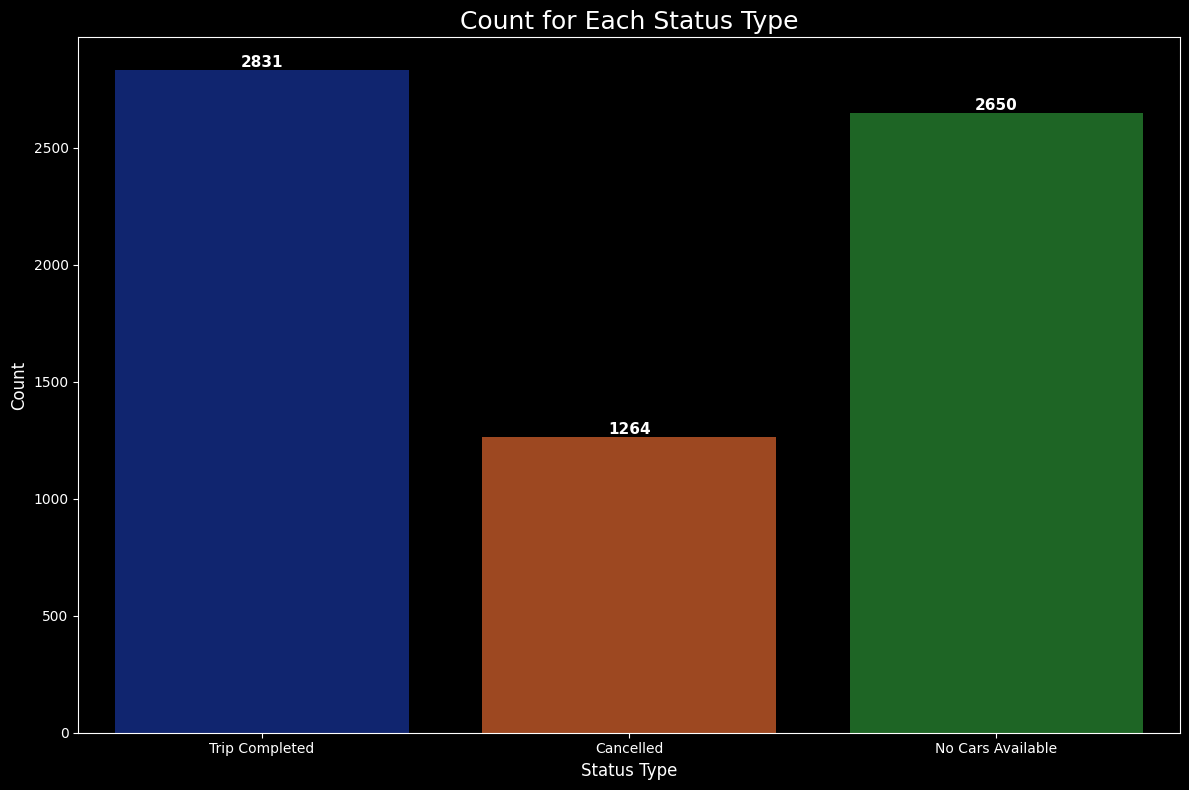

In [20]:
# Chart - 1 visualization code
plt.style.use('dark_background')
md.columns = md.columns.str.strip()
plt.figure(figsize=(12, 8))

ax = sns.countplot(x='Status', data=md, hue='Status', palette='dark', legend=False)

plt.title('Count for Each Status Type', fontsize=18)
plt.xlabel('Status Type', fontsize=12)
plt.ylabel('Count', fontsize=12)

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()

    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Count Plot (Bar Chart) because it is suitable for showing the number of records in each Status category. It makes it easy to compare the frequency of different status types and identify which status occurs most and least frequently.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of records across different status types. It helps identify which status has the highest and lowest number of records. A higher count indicates that the particular status is more common in the dataset, while a lower count indicates fewer records.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand the overall status distribution and identify areas that need attention. For example, if a negative or incomplete status has a high count, the business can investigate the reasons and take corrective actions.

A high number of unfavorable statuses may indicate potential negative business growth because it could represent issues such as failed transactions, inactive customers, cancelled orders, or unresolved cases (depending on what the Status column represents). Therefore, monitoring the status distribution can help the business take timely action and improve performance.

#### Chart - 2

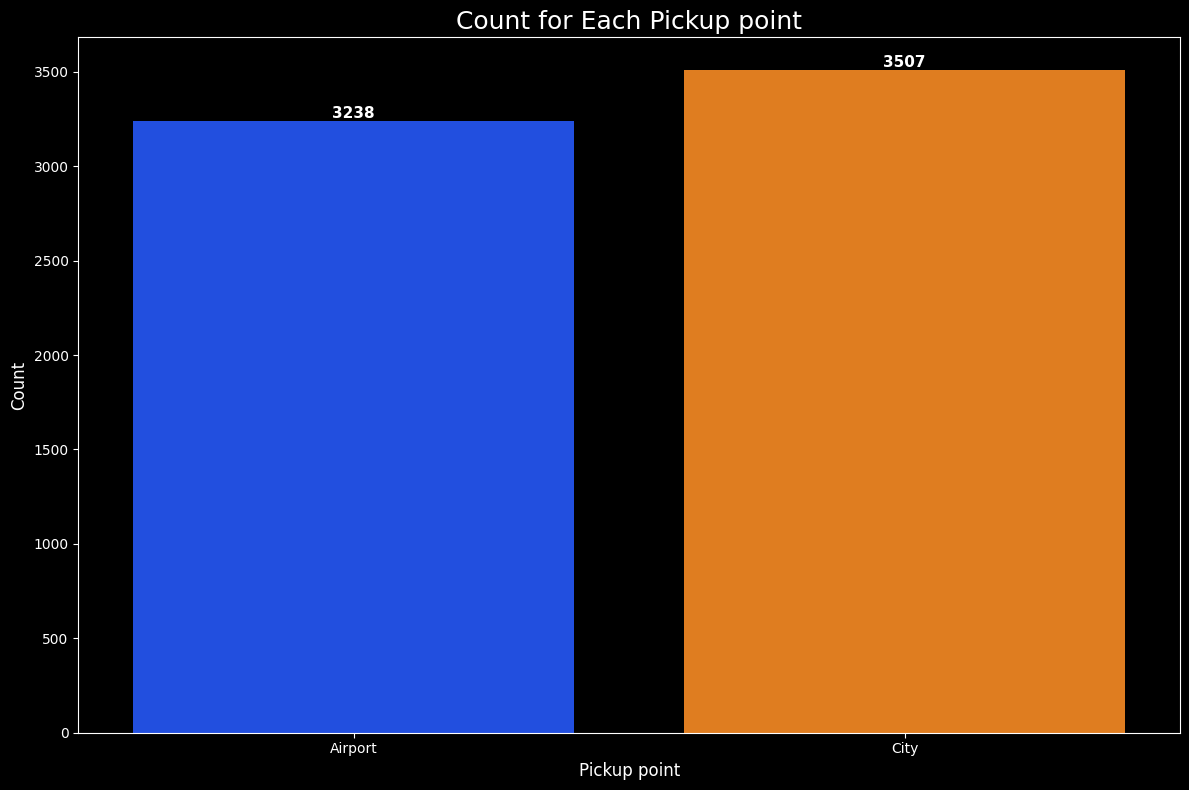

In [21]:
# Chart - 2 visualization code
plt.style.use('dark_background')
md.columns = md.columns.str.strip()
plt.figure(figsize=(12, 8))

ax = sns.countplot(
    x='Pickup point',
    data=md,
    hue='Pickup point',
    palette='bright',
    legend=False
)

plt.title('Count for Each Pickup point', fontsize=18)
plt.xlabel('Pickup point', fontsize=12)
plt.ylabel('Count', fontsize=12)

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()

    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Count Plot (Bar Chart) because it is suitable for comparing the number of records for each Pickup Point. It clearly shows which pickup locations have the highest and lowest number of bookings.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of bookings among different pickup points. It helps identify which pickup point has the highest number of bookings and which has the lowest. This gives an understanding of where most customers are starting their trips.

 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand customer demand at different pickup locations. The business can allocate more vehicles and resources to pickup points with higher demand and improve availability.

A pickup point with very low demand may indicate lower customer usage or accessibility issues. This could have a negative impact on business growth if resources are not properly utilized. The business can investigate the reasons for low demand and take appropriate action to improve service at those locations.

#### Chart - 3

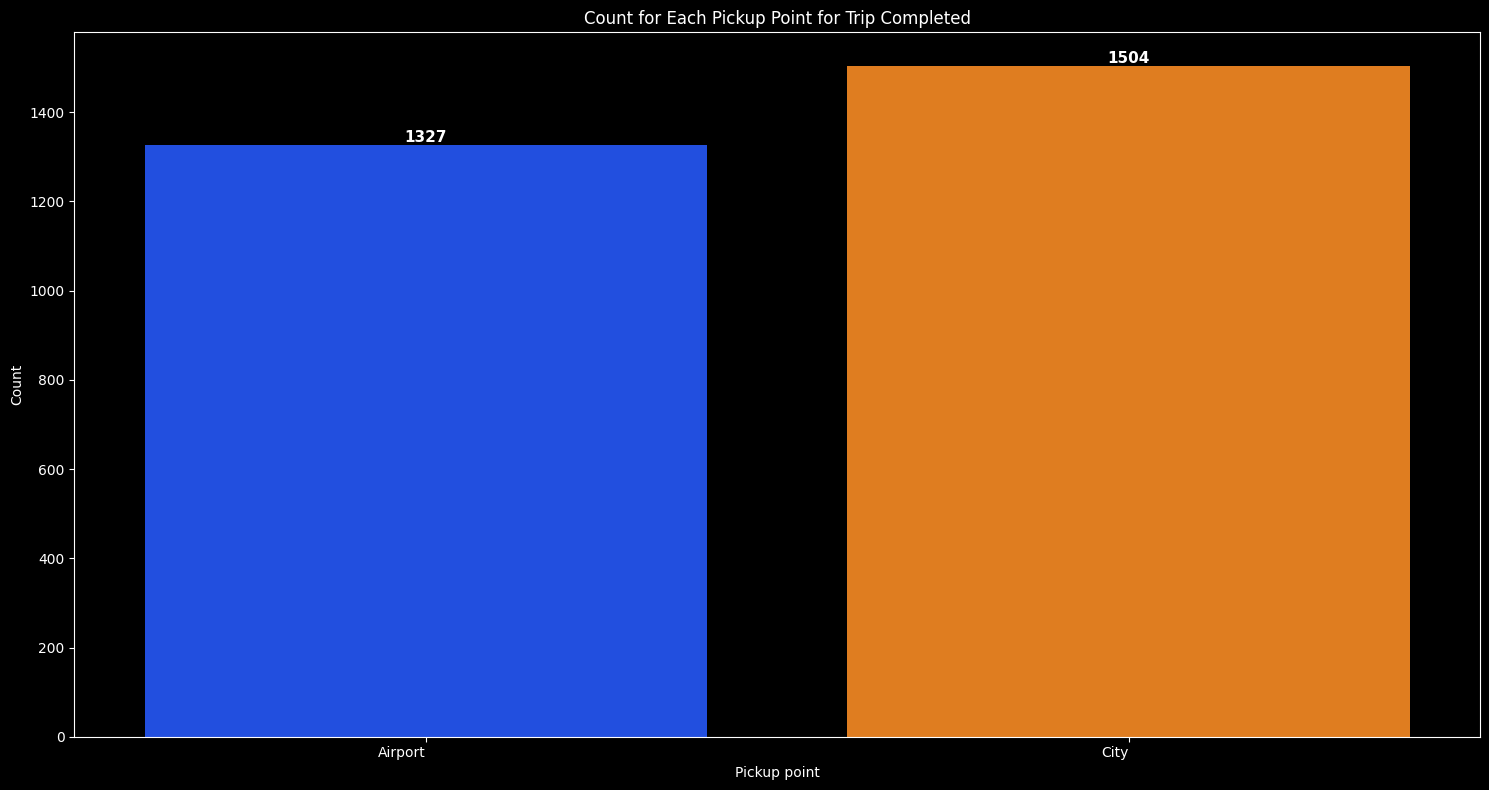

In [22]:
# Chart - 3 visualization code
plt.style.use('dark_background')

trip_c = md[md.Status == 'Trip Completed'].groupby('Pickup point')['Pickup point'].count()
trip_c1 = pd.DataFrame(trip_c)

# Rename the count column
trip_c1.rename(columns={'Pickup point': 'count'}, inplace=True)
trip_c1.reset_index(inplace=True)

# Create a bar plot
plt.figure(figsize=(15, 8))  # Adjust figure size
ax = sns.barplot(data=trip_c1, x='Pickup point', y='count', hue='Pickup point', palette='bright')

# Rotate x-axis labels for better readability
plt.xticks(rotation=0, ha='right')
plt.xlabel('Pickup point')
plt.ylabel('Count')
plt.title('Count for Each Pickup Point for Trip Completed')

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()

    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Bar Chart because it is useful for comparing the number of completed trips across different pickup points. It makes it easy to identify which pickup point has the highest and lowest number of successful trips.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the number of completed trips from each pickup point. It helps identify which pickup location contributes the most to completed trips and which location has fewer completed trips.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand which pickup points generate more successful trips. The company can focus on maintaining sufficient vehicle availability and improving service at high-performing pickup points.

Pickup points with a low number of completed trips may indicate lower demand or operational problems such as vehicle unavailability or trip cancellations. This can negatively affect business growth, so the company can investigate these locations and take corrective actions to increase successful bookings.

#### Chart - 4

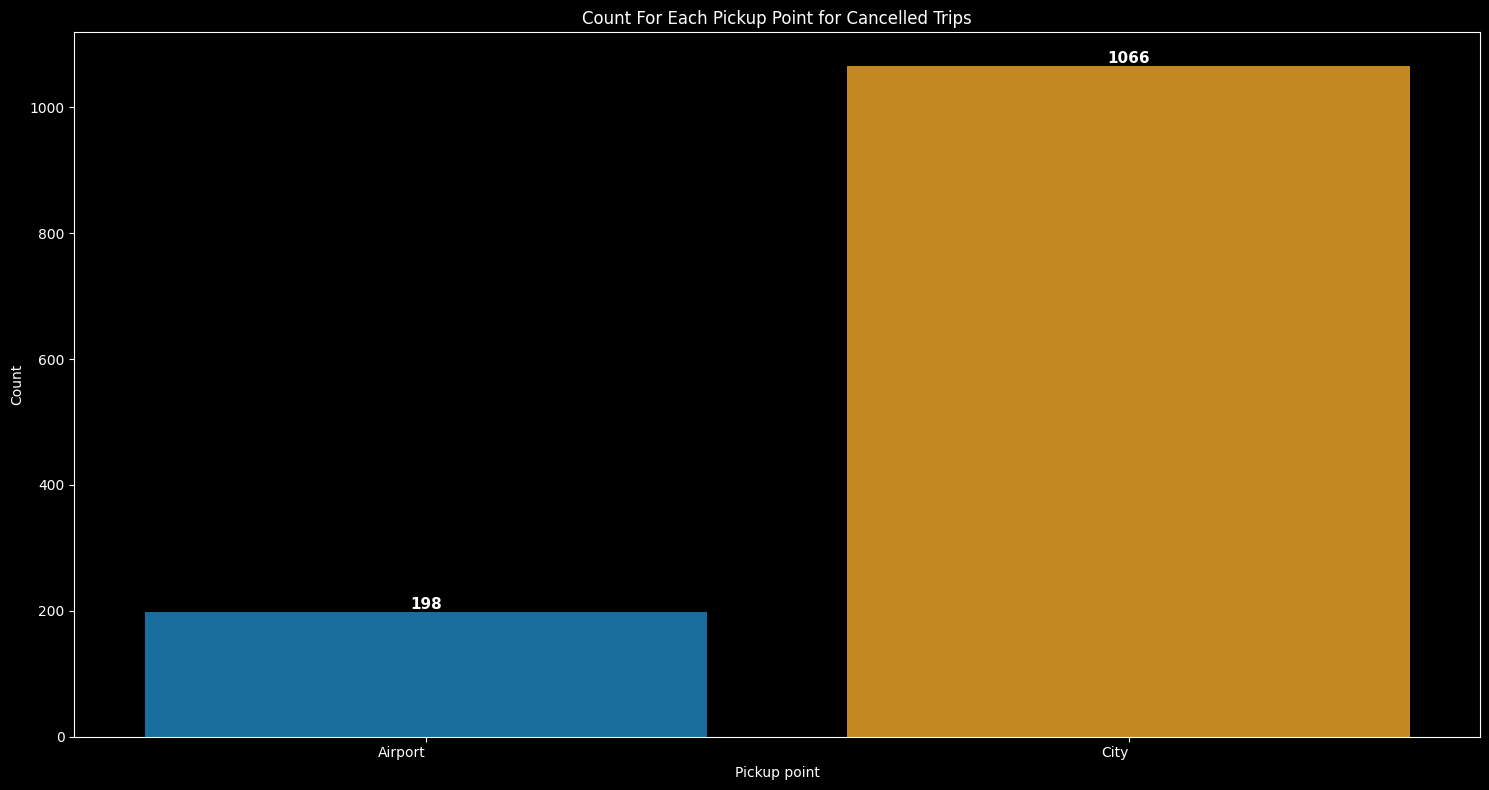

In [23]:
# Chart - 4 visualization code
plt.style.use('dark_background')

cancel = md[md.Status == 'Cancelled'].groupby('Pickup point')['Pickup point'].count()
cancel_1 = pd.DataFrame(cancel)

# Rename the count column
cancel_1.rename(columns={'Pickup point': 'count'}, inplace=True)
cancel_1.reset_index(inplace=True)

# Create a bar plot
plt.figure(figsize=(15, 8))  # Adjust figure size
ax = sns.barplot(
    data=cancel_1,
    x='Pickup point',
    y='count',
    hue='Pickup point',
    palette='colorblind'
)

# Rotate x-axis labels for better readability
plt.xticks(rotation=0, ha='right')
plt.xlabel('Pickup point')
plt.ylabel('Count')
plt.title('Count For Each Pickup Point for Cancelled Trips')

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()

    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Bar Chart because it clearly compares the number of cancelled trips across different pickup points. It helps identify which pickup point has the highest and lowest number of cancellations.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of cancelled trips across different pickup points. It helps identify the pickup point where the number of cancellations is highest and the pickup point where cancellations are relatively lower.

3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify pickup locations with a high cancellation rate and investigate the possible reasons behind the cancellations.

A high number of cancelled trips can have a negative impact on business growth because it may lead to lost revenue, reduced customer satisfaction, and inefficient use of resources. The company can analyze these pickup points and take corrective actions, such as improving vehicle availability and reducing waiting time, to reduce cancellations.

#### Chart - 5

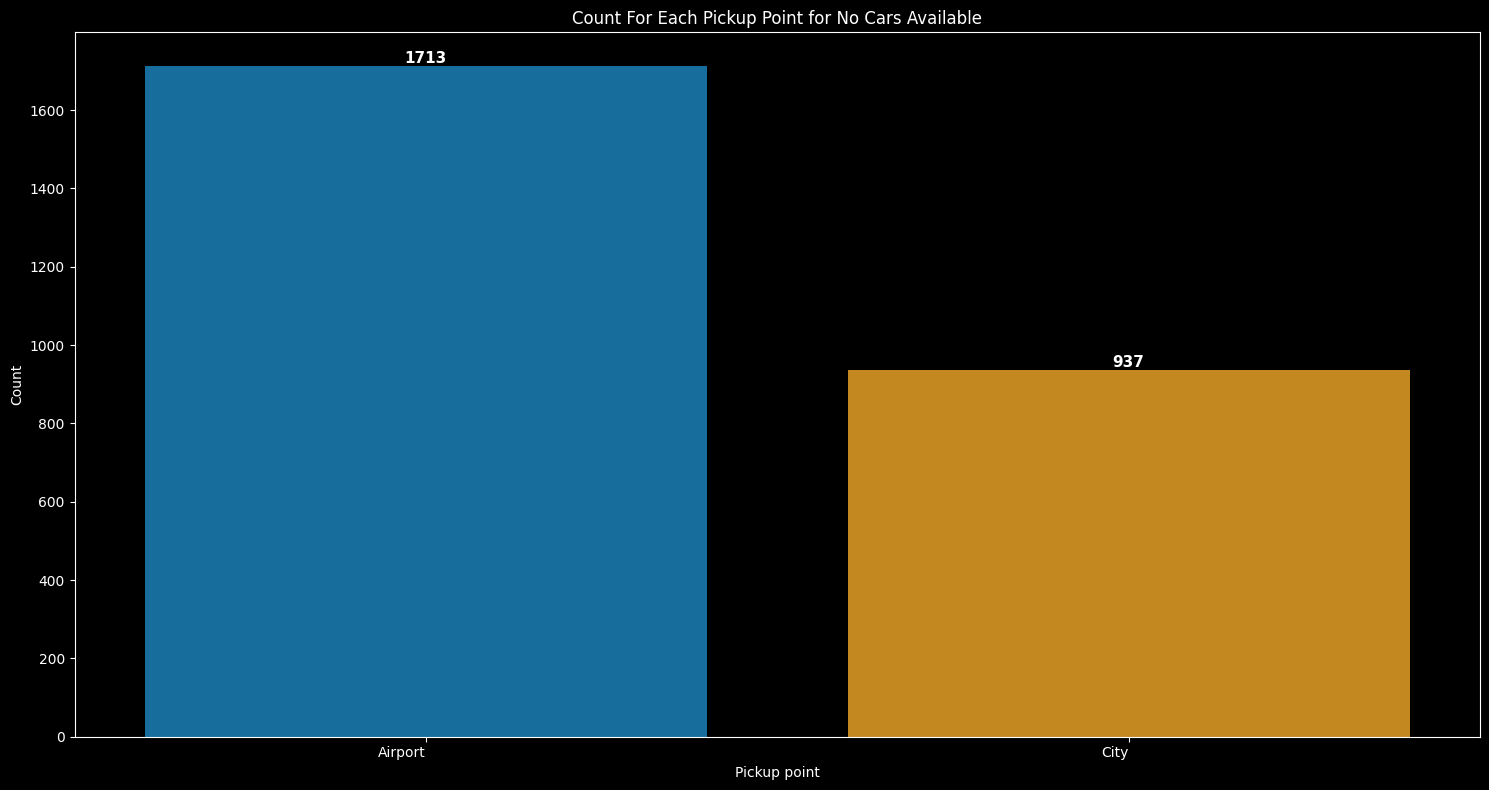

In [24]:
# Chart - 5 visualization code
plt.style.use('dark_background')

nocars = md[md.Status == 'No Cars Available'].groupby('Pickup point')['Pickup point'].count()
nocars_1 = pd.DataFrame(nocars)

# Rename the count column
nocars_1.rename(columns={'Pickup point': 'count'}, inplace=True)
nocars_1.reset_index(inplace=True)

# Create a bar plot
plt.figure(figsize=(15, 8))  # Adjust figure size
ax = sns.barplot(
    data=nocars_1,
    x='Pickup point',
    y='count',
    hue='Pickup point',
    palette='colorblind'
)

# Rotate x-axis labels for better readability
plt.xticks(rotation=0, ha='right')
plt.xlabel('Pickup point')
plt.ylabel('Count')
plt.title('Count For Each Pickup Point for No Cars Available')

for p in ax.patches:
    count = int(p.get_height())
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(
        str(count),
        (x, y),
        ha='center',
        va='bottom',
        fontsize=11,
        color='white',
        fontweight='bold'
    )

plt.grid(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Bar Chart because it clearly compares the number of “No Cars Available” cases across different pickup points. It helps identify which pickup point faces the highest shortage of vehicles.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the number of times cars were unavailable at each pickup point. It helps identify the pickup location with the highest number of vehicle shortages and the location with the lowest number of shortages.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify pickup points where vehicle availability is a major issue. The company can increase the number of available vehicles in locations with high shortages.

A high number of “No Cars Available” cases can negatively affect business growth because customers may be unable to complete their trips, resulting in lost revenue and lower customer satisfaction. Improving vehicle availability can help increase completed trips and improve the overall customer experience.

#### Chart - 6

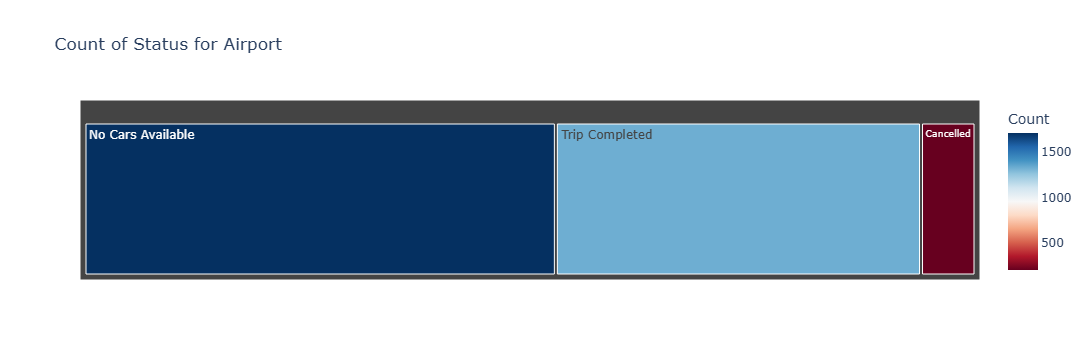

In [25]:
# Chart - 6 visualization code
plt.style.use('dark_background')

# Ensure clean column names
md.columns = md.columns.str.strip()

# Filter for Pickup point = 'Airport'
airport_df = md[md['Pickup point'].str.strip() == 'Airport']

# Group by Status and count
type_count = airport_df['Status'].value_counts().reset_index()
type_count.columns = ['Status', 'Count']

# Create the treemap
fig = px.treemap(
    type_count,
    path=['Status'],
    values='Count',
    title='Count of Status for Airport',
    color='Count',
    color_continuous_scale='RdBu'
)

# Show the plot
fig.show()

##### 1. Why did you pick the specific chart?

I selected a Treemap because it is useful for showing the proportion and distribution of different status types at the Airport pickup point. The size of each section makes it easy to compare which status has the highest and lowest count.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of different trip statuses specifically for Airport pickups. It helps identify which status occurs most frequently at the Airport and which statuses occur less frequently.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand how Airport trips are performing and identify operational issues.

If “No Cars Available” or “Cancelled” has a high count, it can negatively affect business growth by causing lost bookings, reduced revenue, and customer dissatisfaction. The company can focus on improving vehicle availability and reducing cancellations at the Airport to increase successful trip completion.

#### Chart - 7

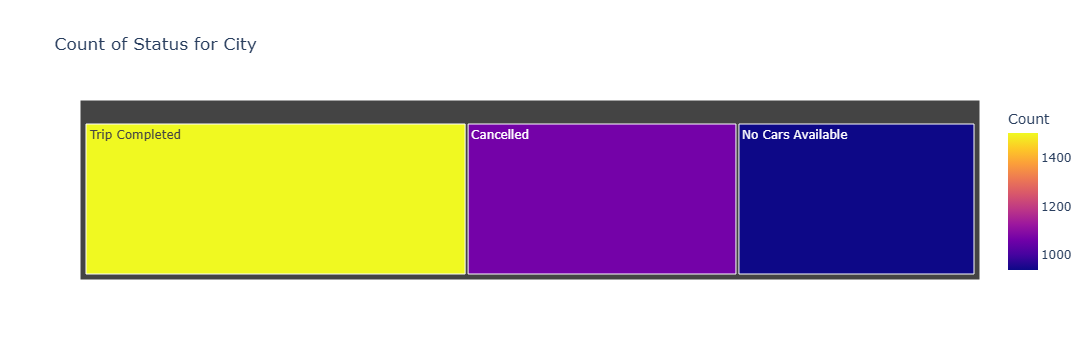

In [26]:
# Chart - 7 visualization code

plt.style.use('dark_background')

# Ensure clean column names
md.columns = md.columns.str.strip()

# Filter for Pickup point = 'City'
City_df = md[md['Pickup point'].str.strip() == 'City']

# Group by Status and count
City_df_count = City_df['Status'].value_counts().reset_index()
City_df_count.columns = ['Status', 'Count']

# Create the treemap
fig = px.treemap(
    City_df_count,
    path=['Status'],
    values='Count',
    title='Count of Status for City',
    color='Count',
    color_discrete_map={'?': 'lightgrey', 'Lunch': 'gold', 'Dinner': 'darkblue'}
)

# Show the plot
fig.show()


##### 1. Why did you pick the specific chart?

I selected a Treemap because it is useful for visualizing the distribution of different trip statuses for the City pickup point. The size of each section makes it easy to compare the number of trips under each status.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the count of different trip statuses for City pickups. It helps identify which status occurs most frequently and which status has the lowest count. This provides an overview of the performance of City pickup trips.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand the performance and operational issues at City pickup points.
If “Cancelled” or “No Cars Available” has a high count, it can negatively affect business growth by causing lost revenue and customer dissatisfaction. The company can focus on reducing cancellations and improving vehicle availability to increase the number of successfully completed trips.

#### Chart - 8

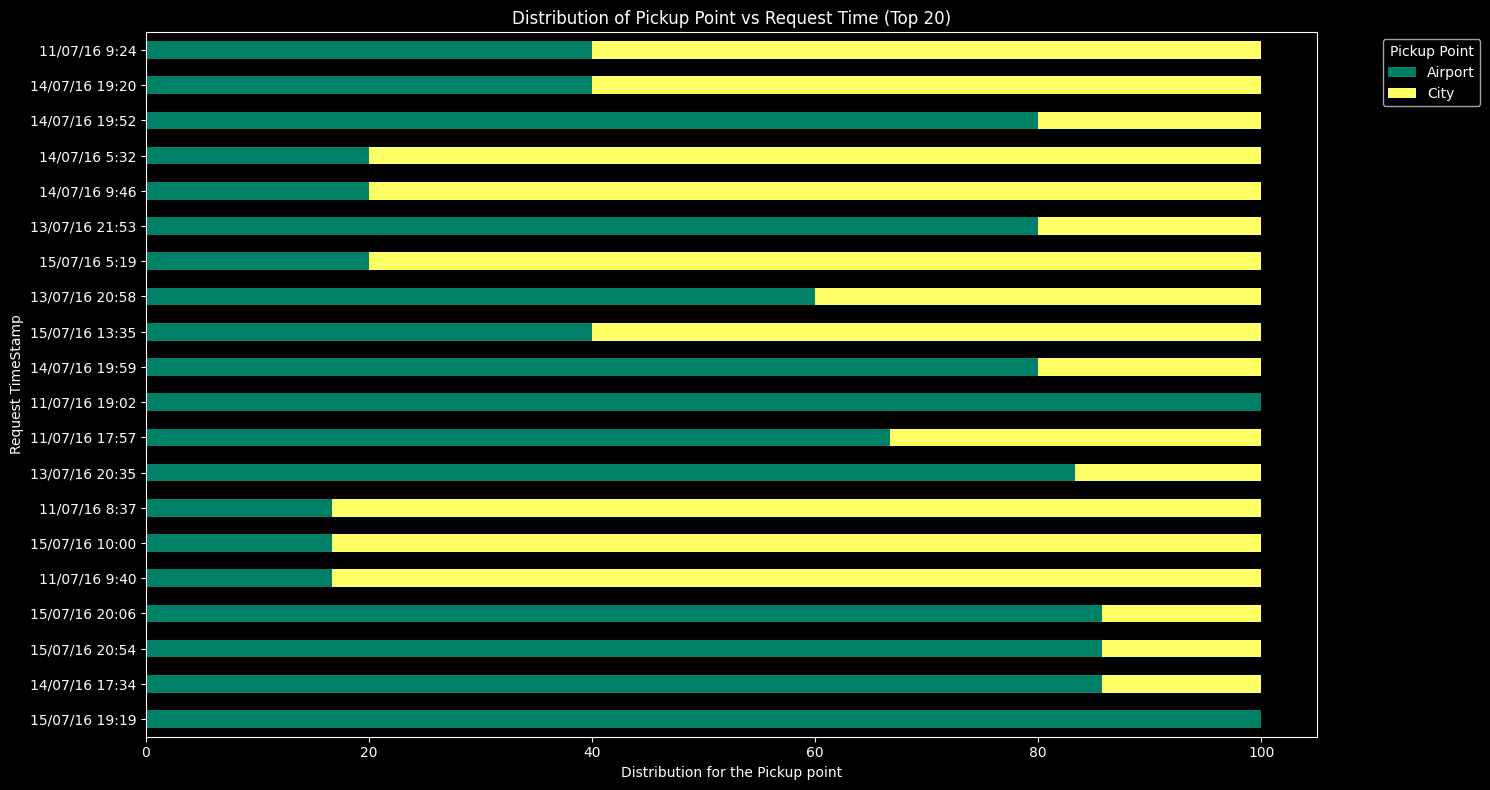

In [27]:
# Chart - 8 visualization code
P_1 = md.groupby(['Request timestamp', 'Pickup point']).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
P_11 = P_1.div(P_1.sum(axis=1), axis=0) * 100

# Select top 20 stations by total trip count (sum of all user types per station)
top_P = P_1.sum(axis=1).sort_values(ascending=False).head(20).index
P_top20 = P_11.loc[top_P]

# Plot stacked bar chart for top 20 stations
fig, ax = plt.subplots(figsize=(15, 8))  # Adjust figure size
P_top20.plot(kind="barh", stacked=True, colormap="summer", ax=ax)

# Labels and title
plt.xlabel("Distribution for the Pickup point")
plt.ylabel("Request TimeStamp")
plt.title("Distribution of Pickup Point vs Request Time (Top 20)")
plt.legend(title="Pickup Point", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a 100% Stacked Bar Chart because it is useful for comparing the distribution of different pickup points across request timestamps. It shows the proportion of each pickup point at different request times, making it easier to identify patterns in customer demand.

##### 2. What is/are the insight(s) found from the chart?

The chart shows how the pickup point distribution changes across different request times. It helps identify the request times when demand is higher and whether customers are more likely to start their trips from the City or Airport pickup point.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand when and where customer demand is higher. This can help the company plan vehicle availability and allocate resources according to demand.

If certain request times show a high concentration of demand but insufficient vehicle availability, it can lead to cancellations and “No Cars Available” cases, negatively affecting revenue and customer satisfaction. By preparing more vehicles during high-demand periods, the company can increase successful trips and improve business performance.

#### Chart - 9

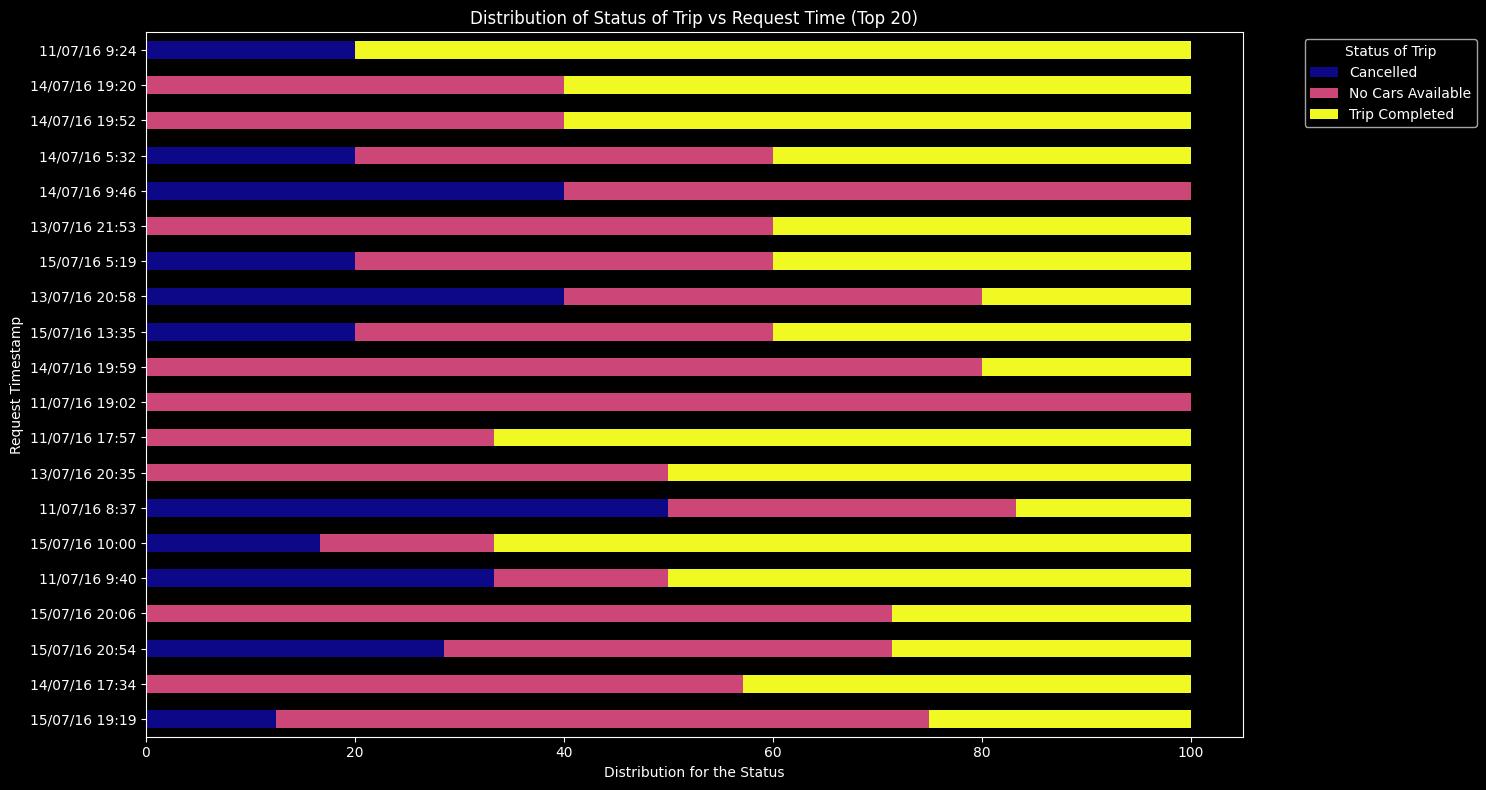

In [28]:
# Chart - 9 visualization code
S_1 = md.groupby(['Request timestamp', 'Status']).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
S_11 = S_1.div(S_1.sum(axis=1), axis=0) * 100

# Select top 20 stations by total trip count (sum of all user types per station)
top_S = S_1.sum(axis=1).sort_values(ascending=False).head(20).index
S_top20 = S_11.loc[top_S]

# Plot stacked bar chart for top 20 stations
fig, ax = plt.subplots(figsize=(15, 8))  # Adjusted figure size
S_top20.plot(kind="barh", stacked=True, colormap="plasma", ax=ax)

# Labels and title
plt.xlabel("Distribution for the Status")
plt.ylabel("Request Timestamp")
plt.title("Distribution of Status of Trip vs Request Time (Top 20)")
plt.legend(title="Status of Trip", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a 100% Stacked Bar Chart because it helps compare the percentage distribution of different trip statuses across request timestamps. It makes it easier to understand how the trip status changes depending on the request time.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of different trip statuses at different request times. It helps identify the request times when completed trips, cancelled trips, or “No Cars Available” cases are more common.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify time periods with higher cancellations or vehicle shortages. The company can use this information to improve vehicle allocation and service availability during high-demand periods.

A high percentage of cancelled trips or “No Cars Available” cases at certain times can negatively affect business growth because it may result in lost revenue and customer dissatisfaction. By increasing vehicle availability and improving operations during these periods, the company can increase completed trips and improve overall business performance.

#### Chart - 10

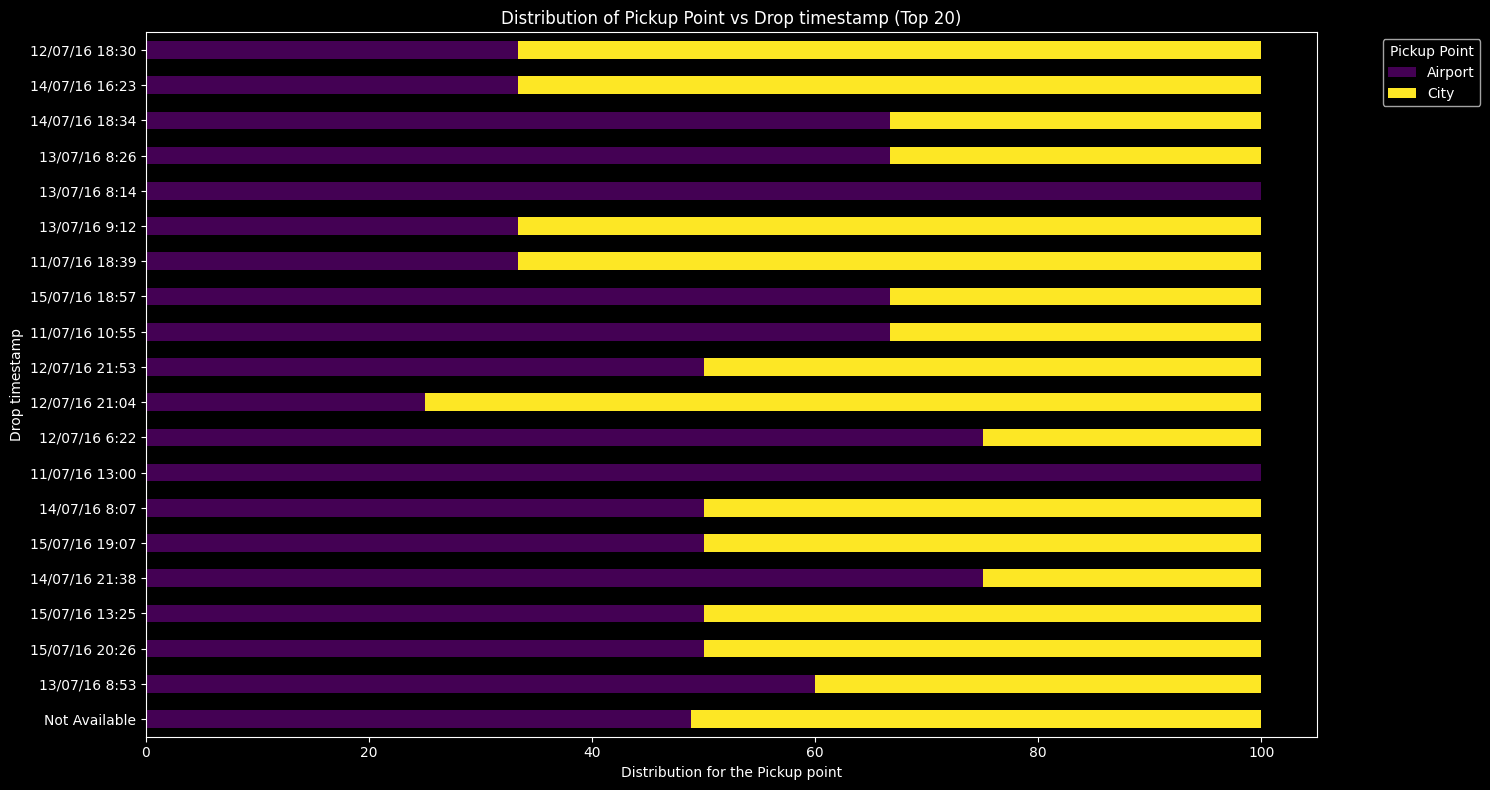

In [29]:
# Chart - 10 visualization code
Pd_1 = md.groupby(["Drop timestamp", "Pickup point"]).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
Pd_11 = Pd_1.div(Pd_1.sum(axis=1), axis=0) * 100

# Select top 20 stations by total trip count (sum of all user types per station)
top_Pd = Pd_1.sum(axis=1).sort_values(ascending=False).head(20).index
Pd_top20 = Pd_11.loc[top_Pd]

# Plot stacked bar chart for top 20 stations
fig, ax = plt.subplots(figsize=(15, 8))  # Adjusted figure size
Pd_top20.plot(kind="barh", stacked=True, colormap="viridis", ax=ax)

# Labels and title
plt.xlabel("Distribution for the Pickup point")
plt.ylabel("Drop timestamp")
plt.title("Distribution of Pickup Point vs Drop timestamp (Top 20)")
plt.legend(title="Pickup Point", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a 100% Stacked Bar Chart because it helps compare the percentage distribution of pickup points across different drop timestamps. It clearly shows how the pickup point distribution varies based on the time when trips are completed.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of Airport and City pickup points across different drop timestamps. It helps identify the times when trips from each pickup point are more frequent and understand the pattern of completed trips throughout the day.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business understand when trips are most frequently completed and plan vehicle availability and operations accordingly.

If there are specific time periods with high demand but insufficient vehicle availability, it can result in cancellations and lost business opportunities. By allocating vehicles efficiently during these periods, the company can improve service availability, increase completed trips, and improve customer satisfaction.

#### Chart - 11

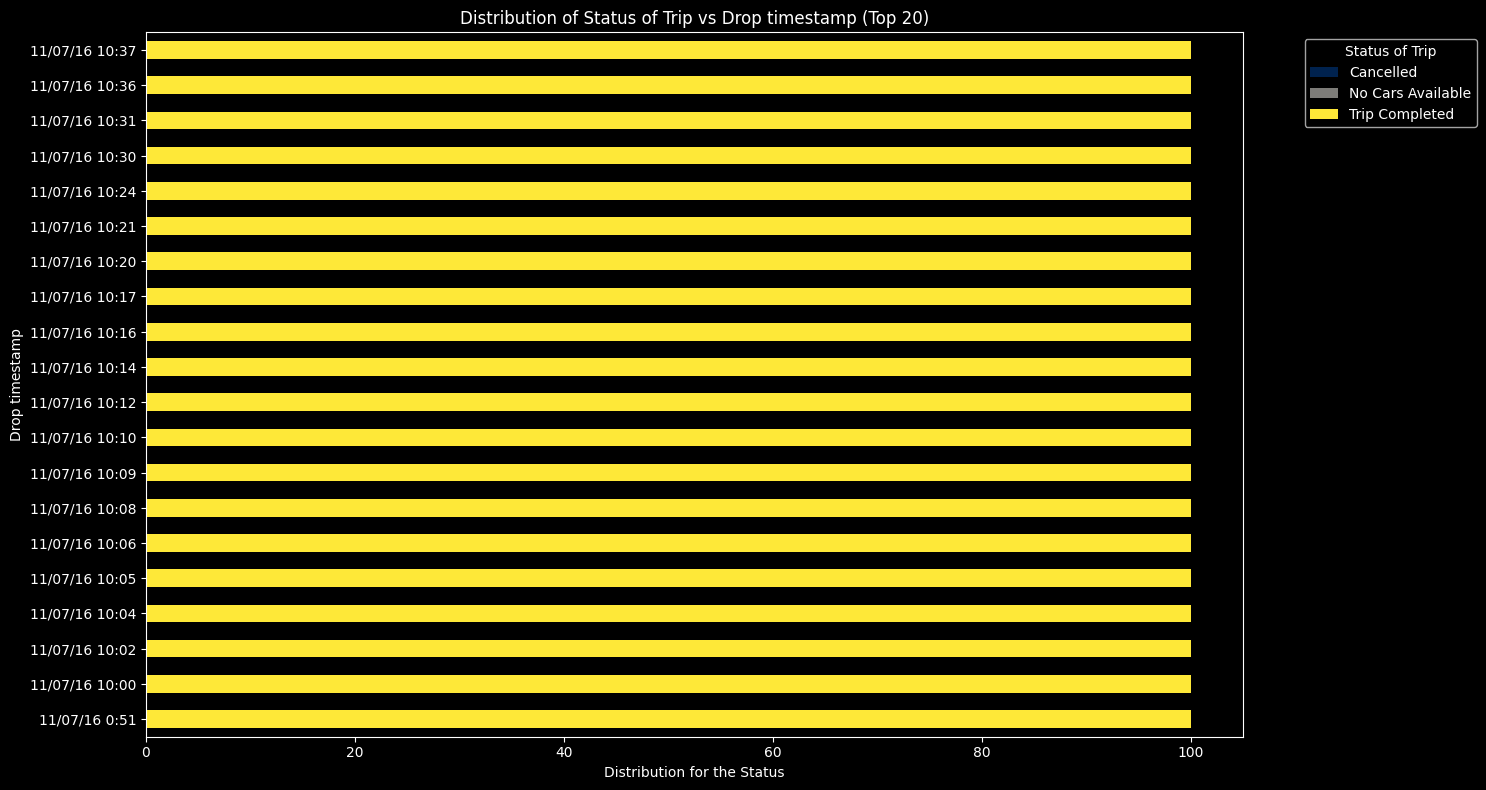

In [30]:
# Chart - 11 visualization code


sd_11 = md.groupby(["Drop timestamp", "Status"]).size().unstack(fill_value=0)

# Normalize the data (percentage distribution)
sd_11 = sd_11.div(sd_11.sum(axis=1), axis=0) * 100

# Select top 20 stations by total trip count
top_sd = sd_11.sum(axis=1).sort_values(ascending=False).head(20).index
sd_top20 = sd_11.loc[top_sd]

# Plot stacked bar chart for top 20 stations
fig, ax = plt.subplots(figsize=(15, 8))
sd_top20.plot(
    kind="barh",
    stacked=True,
    colormap="cividis",
    ax=ax
)

# Labels and title
plt.xlabel("Distribution for the Status")
plt.ylabel("Drop timestamp")
plt.title("Distribution of Status of Trip vs Drop timestamp (Top 20)")

plt.legend(
    title="Status of Trip",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a 100% Stacked Bar Chart because it helps compare the percentage distribution of different trip statuses across drop timestamps. It makes it easy to understand how the status of trips varies at different drop times.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the distribution of different trip statuses at different drop timestamps. It helps identify the times when completed, cancelled, or “No Cars Available” statuses are more common and highlights the overall pattern of trip outcomes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify time periods with a higher percentage of unsuccessful trips and understand where operational improvements are needed.

A high percentage of cancelled trips or “No Cars Available” cases during particular time periods can negatively affect business growth by causing lost revenue and lower customer satisfaction. The company can use these insights to improve vehicle availability and operations during such periods, increasing successful trips and overall business performance.

#### Chart - 12

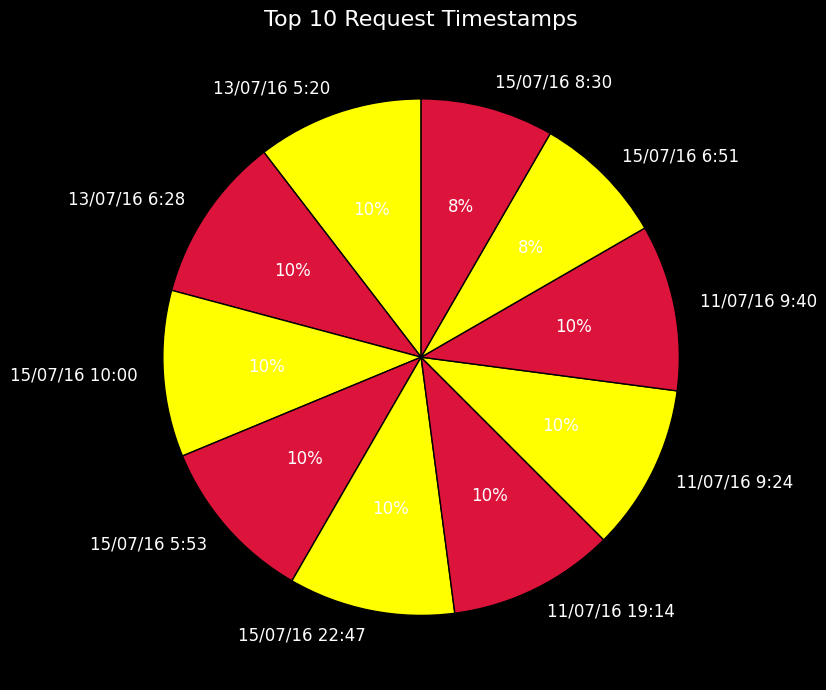

In [35]:
# Chart - 12 visualization code
co = md['Request timestamp'].value_counts().head(10)

# No conversion to int here

plt.figure(figsize=(15, 7))

co.plot(
    kind='pie',
    labels=co.index,  # Keep as strings
    autopct=lambda p: '{:.0f}%'.format(p),
    colors=['yellow', 'crimson'],
    startangle=90,
    wedgeprops={'edgecolor': 'black'},
    textprops={'fontsize': 12, 'color': 'white'}
)

plt.title('Top 10 Request Timestamps', fontsize=16)
plt.ylabel('')
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Pie Chart because it is useful for showing the proportion of requests among the top 10 request timestamps. It makes it easy to compare which timestamps contribute a larger or smaller share of total requests.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the top 10 timestamps with the highest number of requests. It helps identify the time periods when the demand for rides is highest and which timestamps have relatively fewer requests.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help the business identify peak request periods and plan vehicle availability accordingly. Having enough vehicles during high-demand periods can help the company serve more customers and increase completed trips.

If the company cannot meet demand during these peak timestamps, it may result in “No Cars Available” cases or cancellations, which can negatively affect revenue and customer satisfaction. Therefore, understanding peak request times can help improve resource planning and business performance.

#### Chart - 13

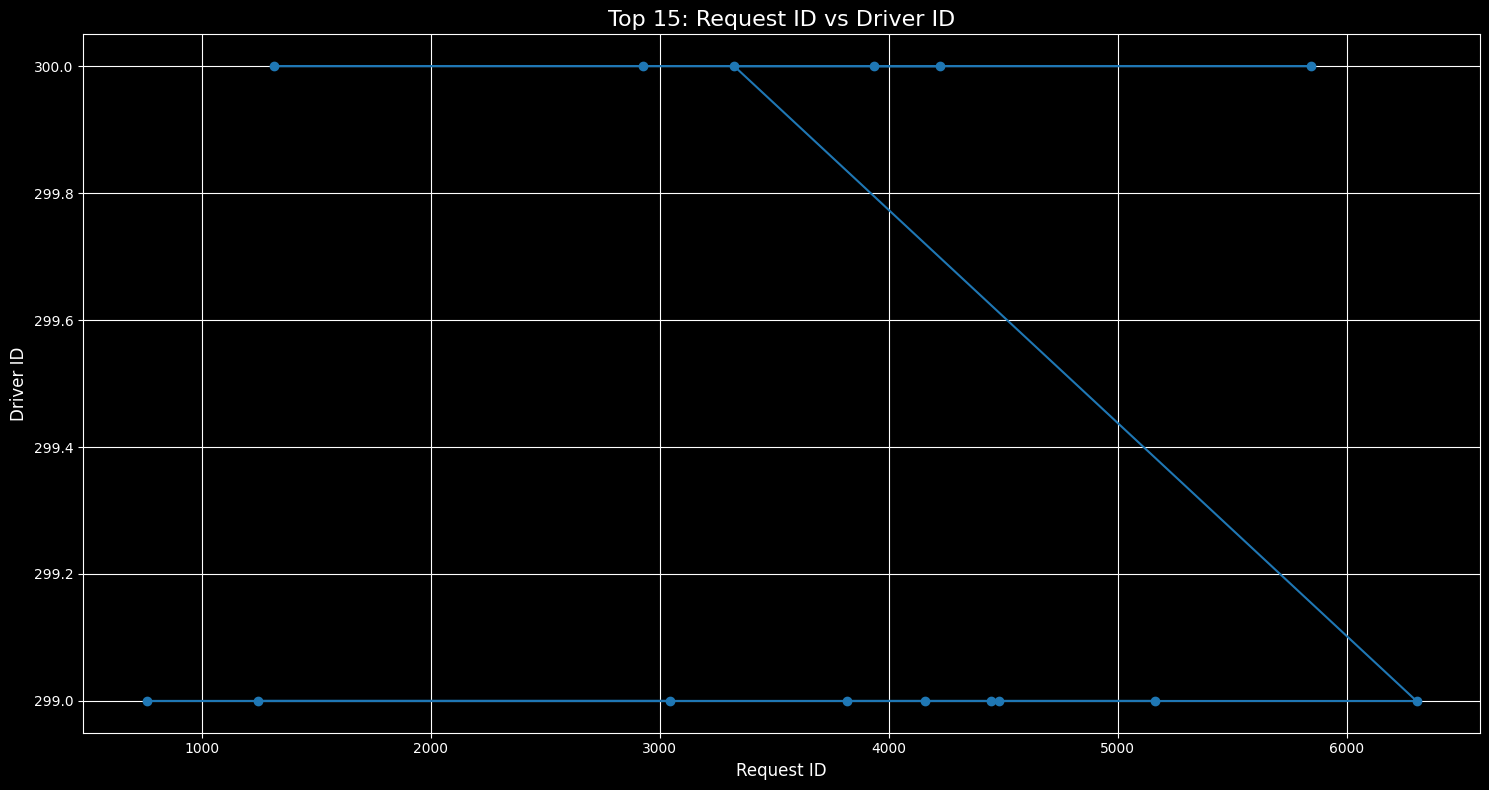

In [32]:
# Chart - 13 visualization code
plt.style.use('dark_background')

# Clean column names
md.columns = md.columns.str.strip()

# Optional: Convert columns to numeric (in case they're strings)
md['Driver id'] = pd.to_numeric(md['Driver id'], errors='coerce')
md['Request id'] = pd.to_numeric(md['Request id'], errors='coerce')

# Drop rows with missing values
md = md.dropna(subset=['Driver id', 'Request id'])

# Sort by Driver id descending and take top 15
top_rd = md[['Request id', 'Driver id']].sort_values(
    by='Driver id', ascending=False
).head(15)

# Plot
plt.figure(figsize=(15, 8))

plt.plot(
    top_rd['Request id'],
    top_rd['Driver id'],
    marker='o',
    color='tab:blue',
    linestyle='-'
)

plt.xlabel("Request ID", fontsize=12)
plt.ylabel("Driver ID", fontsize=12)
plt.title("Top 15: Request ID vs Driver ID", fontsize=16)

plt.grid(True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Line Chart to show the relationship between Request ID and Driver ID for the top 15 records. It makes it easy to compare the Driver IDs associated with different Request IDs.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the Driver IDs corresponding to the selected top 15 Request IDs. It helps identify which driver IDs are associated with the highest driver ID values and observe how driver IDs vary across the selected requests.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This analysis can help the business understand driver assignment patterns and identify unusual or important driver-request relationships. It can support better driver management and assignment decisions. If certain requests are associated with limited or repeated drivers, it may indicate an inefficient driver allocation, which could negatively affect service availability and customer satisfaction.

#### Chart - 14 - Correlation Heatmap

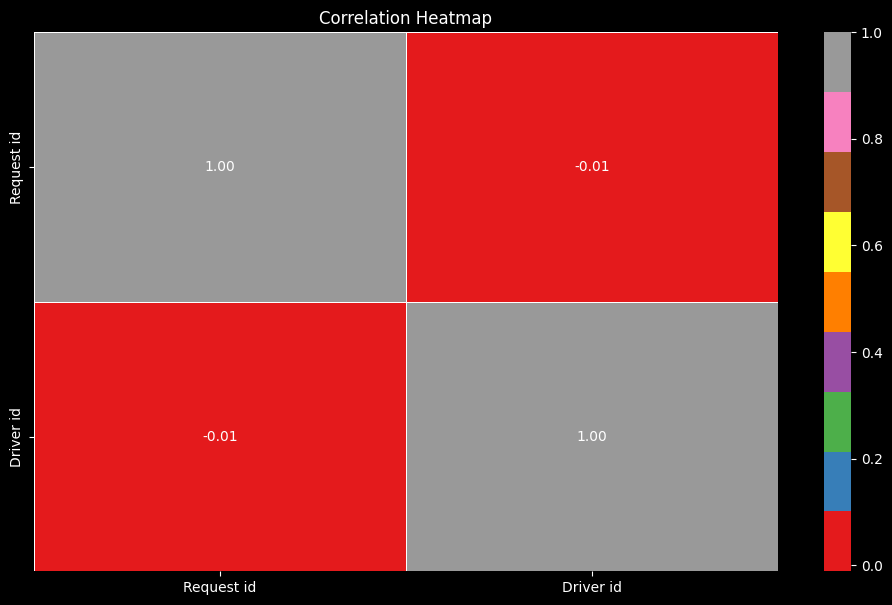

In [36]:
# Correlation Heatmap visualization code

plt.style.use('dark_background')

numerical = md.select_dtypes(include=['int64', 'float64'])

corr_matrix = numerical.corr().fillna(0)

plt.figure(figsize=(12, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="Set1",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

I selected a Correlation Heatmap because it is useful for understanding the relationship between numerical variables. The color and correlation values make it easy to identify whether variables have a strong, weak, positive, or negative relationship.

##### 2. What is/are the insight(s) found from the chart?

The heatmap shows the correlation values between the numerical columns in the dataset. Values closer to +1 indicate a strong positive relationship, values closer to -1 indicate a strong negative relationship, and values close to 0 indicate little or no linear relationship.

#### Chart - 15 - Pair Plot

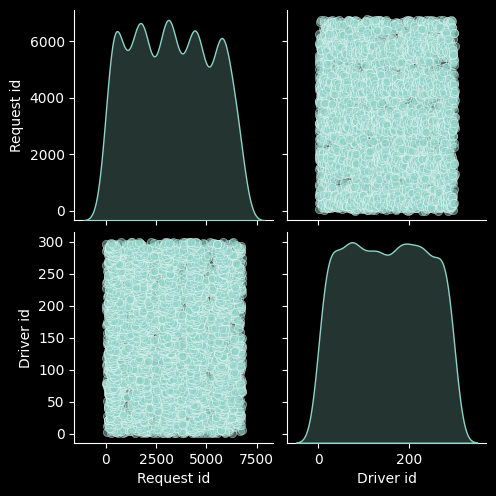

In [38]:
# Pair Plot visualization code
plt.style.use('dark_background')

numerical = md.select_dtypes(include=['int64', 'float64'])

numerical = numerical.dropna(axis=1, thresh=len(numerical) * 0.8)

sns.pairplot(
    numerical,
    diag_kind='kde',
    plot_kws={'alpha': 0.5}
)

plt.show()

##### 1. Why did you pick the specific chart?

I selected a Pair Plot because it helps visualize the relationships between multiple numerical variables at the same time. It makes it easy to identify patterns, trends, and relationships between variables.

##### 2. What is/are the insight(s) found from the chart?

The pair plot shows the relationship between each pair of numerical variables. It helps identify whether variables have a positive, negative, or weak relationship. The diagonal KDE plots show the distribution of each numerical variable.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

I suggest that the client should focus on improving vehicle availability, reducing trip cancellations, and understanding peak demand periods. The analysis shows that demand varies based on pickup locations and request times.

The client can increase the number of available vehicles during peak hours and at high-demand locations such as the City and Airport. They should also identify the reasons for cancellations and “No Cars Available” cases and take corrective actions.

These steps can help increase completed trips, improve customer satisfaction, reduce lost revenue, and achieve better overall business growth.


# **Conclusion**

From the analysis, it is clear that pickup location, request time, trip status, and vehicle availability have an important impact on business performance. The analysis helps identify peak demand periods, completed trips, cancellations, and cases where cars were unavailable.

To improve business performance, the client should focus on increasing vehicle availability during peak hours, reducing cancellations, and efficiently allocating drivers to high-demand locations. These actions can increase successful trips, improve customer satisfaction, reduce revenue loss, and support overall business growth.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***